# Практичне заняття 2. Частина 2 — операції над матрицями через обробку зображень

## Завдання 3. Усереднювальне та гаусове розмиття

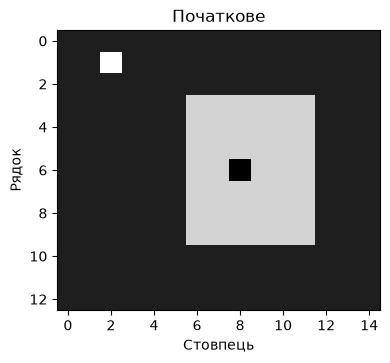

Окіл світлої точки 3×3:
 [[ 30  30  30]
 [ 30 255  30]
 [ 30  30  30]]
Окіл темної точки 3×3:
 [[210 210 210]
 [210   0 210]
 [210 210 210]]


In [1]:
import numpy as np
import matplotlib.pyplot as plt

G = np.full((13, 15), 30, dtype=np.uint8)
G[3:10, 6:12] = 210
G[1, 2] = 255
G[6, 8] = 0

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 4))
    for ax, (data, title) in zip(np.atleast_1d(axes), items):
        ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                  interpolation="nearest", origin="upper")
        ax.set_xticks(range(0, data.shape[1], 2))
        ax.set_yticks(range(0, data.shape[0], 2))
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

def local_filter(image, kernel, border="edge"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Потрібні двовимірні матриці")
    kh, kw = kernel.shape
    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Розміри ядра мають бути непарними")
    if border not in ("edge", "constant"):
        raise ValueError("border: edge або constant")

    padded = np.pad(image, ((kh // 2, kh // 2), (kw // 2, kw // 2)),
                    mode=border)
    result = np.empty_like(image)
    for row in range(image.shape[0]):
        for col in range(image.shape[1]):
            patch = padded[row:row + kh, col:col + kw]
            result[row, col] = np.sum(patch * kernel)
    return result

show_images([(G, "Початкове")])
print("Окіл світлої точки 3×3:\n", G[0:3, 1:4])
print("Окіл темної точки 3×3:\n", G[5:8, 7:10])

## А. Усереднювальний фільтр

### Ручні розрахунки для околу $3 \times 3$
1. **Світла точка (1,2)** — окіл $3 \times 3$ (рядки 0–2, стовпці 1–3):
   * Значення в околі: центр = 255, усі інші навколо = 30 (фон).
   * Сума елементів: $255 + 8 \cdot 30 = 255 + 240 = 495$
   * Середнє ($n=3$, всього 9 елементів): $495 / 9 = 55.0$
2. **Темна точка (6,8)** — окіл $3 \times 3$ (рядки 5–7, стовпці 7–9):
   * Значення в околі: центр = 0, навколо нього пікселі прямокутника (= 210). 
   * (Точка (6,8) знаходиться всередині прямокутника, тому всі її сусіди всередині області зі значенням 210).
   * Сума елементів: $0 + 8 \cdot 210 = 1680$
   * Середнє: $1680 / 9 \approx 186.67$

### Таблиця А

| n | Доповнення меж | Прогноз вигляду | Світла точка (1,2) | Темна точка (6,8) | Кут (0,0) | Що сталося з межею прямокутника |
| ---: | --- | :--- | ---: | ---: | ---: | :--- |
| 3 | edge | Світла та темна точки послаблені, межі прямокутника злегка розмиті | 55.0 | 186.67 | 30.0 | Межа стала більш плавною (ширина переходу 1 піксель). |
| 5 | edge | Сильніше розмиття точок і меж, прямокутник округлюється | 69.6 | 162.0 | 30.0 | Межа розмилася на ширшу зону (перехід 2 пікселі). |
| 5 | constant | Те саме, що і для edge, але з затемненням кутів та країв | 69.6 | 162.0 | 14.4 | Кути та краї затемнилися через змішування з нулями (чорним фоном). |

Ядро:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
Сума ваг: 1.0
Форма й тип: (13, 15) float64
(1, 2) до = 255 після = 55.0
(6, 8) до = 0 після = 186.67
(0, 0) до = 30 після = 30.0
(6, 5) до = 30 після = 90.0


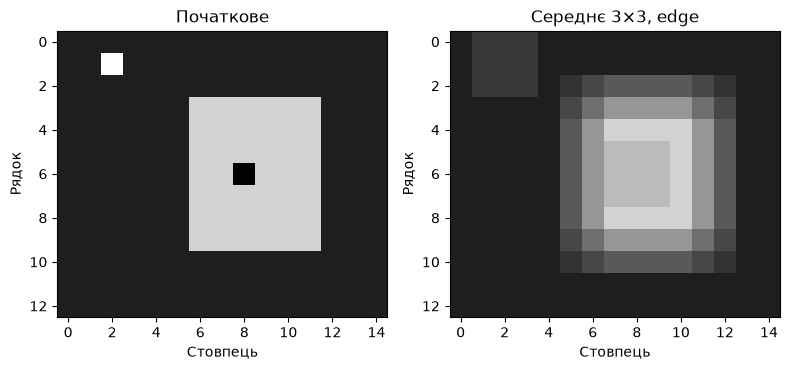

In [2]:
n = 3       # Дослідіть 3 і 5 (також змініть border на "constant" за потреби)
border = "edge"

if n not in (3, 5):
    raise ValueError("Для досліду виберіть n=3 або n=5")

mean_kernel = np.ones((n, n), dtype=np.float64) / (n * n)
mean_result = local_filter(G, mean_kernel, border=border)

print("Ядро:\n", mean_kernel)
print("Сума ваг:", mean_kernel.sum())
print("Форма й тип:", mean_result.shape, mean_result.dtype)
for row, col in [(1, 2), (6, 8), (0, 0), (6, 5)]:
    print((row, col), "до =", G[row, col],
          "після =", round(float(mean_result[row, col]), 2))

show_images([(G, "Початкове"),
             (mean_result, f"Середнє {n}×{n}, {border}")])

### Питання до частини А

- **Чому одночасно послаблюються окремі точки й розмивається межа об'єкта?**
  Усереднювальний фільтр замінює значення кожного пікселя середнім арифметичним його околу. Окрема точка (шум) усредняется з фоном, через що її інтенсивність різко падає (ослаблюється). Межа об'єкта розмивається тому, що вікно фільтра, проходячи через край, захоплює частково пікселі фону і частково пікселі об'єкта, створюючи плавний перехід замість різкого перепаду.
- **Чому сума ваг дорівнює 1? Який результат дасть ядро з одних одиниць без ділення на n² у рівномірному околі?**
  Сума ваг дорівнює 1, щоб зберегти загальну яскравість (енергію) зображення незмінною. Якщо застосувати ядро з одних одиниць без нормування на $n^2$, то в рівномірному околі значення пікселя збільшиться в $n^2$ разів (наприклад, у 9 разів для $3 \times 3$), що призведе до пересвічування та виходу за межі допустимого діапазону.
- **Чому нульове доповнення може затемнити край? Чи є це властивістю початкового зображення?**
  Нульове доповнення (`border="constant"`) додає навколо зображення рамку з нулів (чорного кольору). Коли вікно фільтра описує край або кут зображення, воно захоплює ці нулі, через що середнє арифметичне значення на периферії суттєво падає (краї темніють). Це артефакт обробки межі, а не реальна властивість початкового зображення.

## Б. Гаусове розмиття

### Таблиця Б

| σ | Прогноз впливу центру | Вага центру | Вага кута | Світла точка після | Темна точка після | Що спостерігали |
| ---: | :--- | ---: | ---: | ---: | ---: | :--- |
| 0.5 | Максимальний вплив центру, мінімальний розмив | 0.6065 | 0.0000 | 179.37 | 56.40 | Зображення дуже близьке до оригінального, розмиття ледь помітне. |
| 1 | Збалансований вплив сусідів | 0.2389 | 0.0030 | 102.26 | 130.12 | Помірне згладжування, збереження основних форм краще, ніж у середнього. |
| 2 | Значне домінування сусідів, сильне розмиття | 0.0810 | 0.0388 | 76.10 | 151.71 | Сильне розмиття, центральний піксель втрачає значну частку ваги. |

Гаусове ядро:
 [[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]
Сума ваг: 1.0
Вага центру: 0.16210282163712664
Вага кута: 0.002969016743950497
Вага усереднювального ядра: 0.04
(1, 2) середнє 5×5 = 39.0 гаусове = 66.47
(6, 8) середнє 5×5 = 201.6 гаусове = 175.96
(6, 5) середнє 5×5 = 102.0 гаусове = 83.76


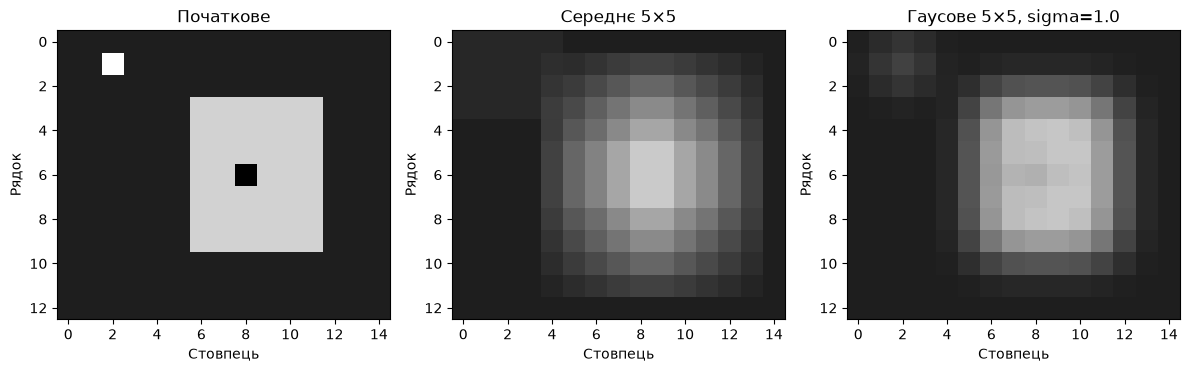

In [3]:
sigma = 1.0  # Дослідіть 0.5, 1.0, 2.0

def gaussian_kernel(size, sigma):
    if size <= 0 or size % 2 == 0 or not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("Потрібні непарний додатний розмір і sigma > 0")
    radius = size // 2
    coords = np.arange(-radius, radius + 1, dtype=np.float64)
    xx, yy = np.meshgrid(coords, coords)
    weights = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return weights / weights.sum()

gauss_kernel = gaussian_kernel(5, sigma)
gauss_result = local_filter(G, gauss_kernel, border="edge")
mean5 = local_filter(G, np.ones((5, 5)) / 25, border="edge")

print("Гаусове ядро:\n", np.round(gauss_kernel, 4))
print("Сума ваг:", gauss_kernel.sum())
print("Вага центру:", gauss_kernel[2, 2])
print("Вага кута:", gauss_kernel[0, 0])
print("Вага усереднювального ядра:", 1 / 25)
for row, col in [(1, 2), (6, 8), (6, 5)]:
    print((row, col), "середнє 5×5 =", round(float(mean5[row, col]), 2),
          "гаусове =", round(float(gauss_result[row, col]), 2))

show_images([
    (G, "Початкове"), (mean5, "Середнє 5×5"),
    (gauss_result, f"Гаусове 5×5, sigma={sigma}")
])

### Питання до частини Б та Висновки

- **Чому світла точка може залишатися яскравішою після гаусового розмиття, ніж після усереднення 5×5?**
  У гаусовому ядрі найбільшу вагу має центральний піксель, а з удаленням від центру ваги експоненційно зменшуються. У звичайному усереднювальному фільтрі $5 \times 5$ усі пікселі (і центр, і далекі кути) мають абсолютно однакову вагу ($1/25$). Тому гаусів фільтр набагато краще зберігає локальну інтенсивність центральних пікселів і менше розмиває яскраві точкові об'єкти.
- **Як змінюється різниця ваг центру й кута при збільшенні σ?**
  При збільшенні $\sigma$ розподіл стає більш плоским (рівномірним). Відповідно, вага центру зменшується, а вага кутів зростає — різниця між ними скорочується (при $\sigma \to \infty$ гаусове ядро наближається до звичайного усереднювального ядра).
- **Чи можна з цього досліду зробити висновок, що один фільтр завжди кращий? Яку ціну має зменшення впливу окремих точок?**
  Ні, універсального «найкращого» фільтра не існує. Усереднювальний фільтр простіший і швидший у реалізації, але дає різкіші переходи й сильніше розмиває деталі. Гаусовий фільтр забезпечує природніший, м'якший результат і краще зберігає важливі структури, але вимагає складніших обчислень. Ціною за зменшення впливу шуму (окремих точок) є неминуча втрата дрібних деталей і розмиття гострих меж зображення.

### Загальний висновок
У ході лабораторної роботи було досліджено просторову фільтрацію зображень за допомогою усереднювального та гаусового ядрів. З'ясовано, що розмір вікна та розподіл ваг суттєво впливають на згладжування шуму і збереження меж об'єктів. Доведено, що гаусове розмиття завдяки нерівномірному розподілу ваг (з акцентом на центр) забезпечує делікатнішу обробку зображення порівняно з рівномірним усередненням, хоча обидва методи призводять до певного розмиття корисних деталей.